In [2]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

import data_utils
from importlib import reload

# Reload the helper so notebook kernels pick up edits made during exploration.
data_utils = reload(data_utils)
plot_bump = data_utils.plot_bump

data = {}
for f in sorted(Path("data_clean").glob("*.csv")):
    data[f.stem] = pd.read_csv(f)

print(list(data.keys()))

['Iisingintie_Acc1_m800_RDMC_2026-05-06_123750', 'Iisingintie_Acc1_m801_RDMC_2026-05-06_124454', 'Iisingintie_Acc1_m802_RDMC_2026-05-06_125211', 'Kaittiaisentie_Acc1_RDMC_2026-05-06_132147', 'sinetänsalmentie_Acc1_m792_RDMC_2026-05-06_112539', 'sinetänsalmentie_Acc1_m793_RDMC_2026-05-06_112757', 'sinetänsalmentie_Acc1_m794_RDMC_2026-05-06_112959', 'sinetänsalmentie_Acc1_m795_RDMC_2026-05-06_113156']


In [3]:
Path("figures").mkdir(exist_ok=True)

### Section 1: what does a bump look like?

#### 2: where are the frost heaves in the 80 km/h drive?

In [4]:
df = data["Iisingintie_Acc1_m800_RDMC_2026-05-06_123750"]

heave = df["muu"] == 1
starts = df.loc[heave & ~heave.shift(fill_value=False), "Loc(m)"]
print(starts.round().tolist())

[4227.0, 4791.0, 4932.0, 5046.0, 5168.0, 5371.0, 5388.0, 5658.0, 6245.0, 6598.0, 6702.0]


#### 3: zoom in on one bump, in three sensors at once

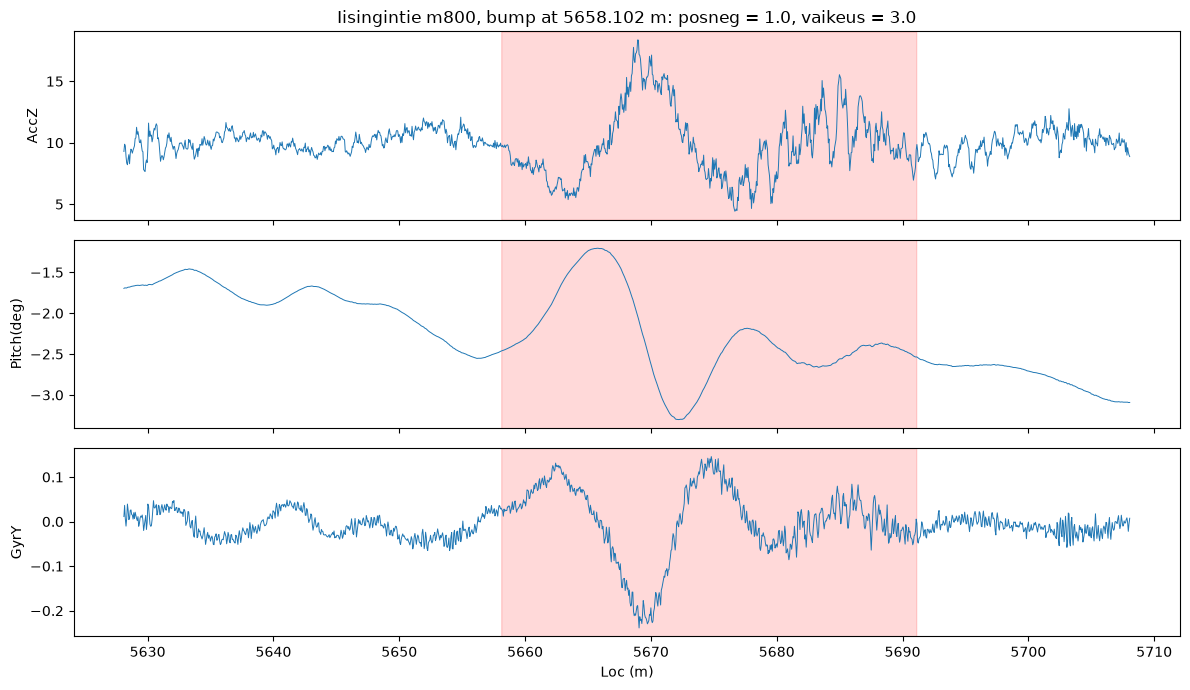

In [5]:
center = starts.iloc[7]          # the first bump; try others from the list above
part = df[df["Loc(m)"].between(center - 30, center + 50)]

fig, axes = plt.subplots(3, 1, figsize=(12, 7), sharex=True)
for ax, col in zip(axes, ["AccZ", "Pitch(deg)", "GyrY"]):
    ax.plot(part["Loc(m)"], part[col], linewidth=0.7)
    ax.fill_between(part["Loc(m)"], 0, 1, where=part["muu"] == 1,
                    transform=ax.get_xaxis_transform(), color="red", alpha=0.15)
    ax.set_ylabel(col)

row = part[part["muu"] == 1].iloc[0]
axes[0].set_title(f"Iisingintie m800, bump at {center} m: posneg = {row['posneg']}, vaikeus = {row['vaikeus']}")
axes[-1].set_xlabel("Loc (m)")
plt.tight_layout()
plt.show()

* Most of the time, inside a bump, the signal fluctuates more. Outside it's calm

* That's exactly what model will use later. When we cut the road into windows, we’ll compute numbers like “how much does the signal vary in this window?” (standard deviation) or “how big is the biggest swing?” (peak-to-peak). A window with a bump should score high and a calm window low.

### Section 2: does an up bump look different from a down bump?

#### 1: list the bumps with their type and size

In [6]:
starts_idx = df.index[heave & ~heave.shift(fill_value=False)]
bumps = df.loc[starts_idx, ["Loc(m)", "posneg", "vaikeus"]].round(0)
print(bumps.to_string(index=False))

 Loc(m)  posneg  vaikeus
 4227.0       1        5
 4791.0       1        3
 4932.0       1        1
 5046.0       1        3
 5168.0       1        5
 5371.0       1        1
 5388.0       1        2
 5658.0       1        3
 6245.0       1        5
 6598.0       1        5
 6702.0       1        5


* Problem: Only 1 values in posneg

In [ ]:
# Look for the highest posneg value in the raw files
for f in sorted(Path("../dataset").glob("*.txt")):
    raw = pd.read_csv(f, sep="\t", dtype=str)
    posneg = pd.to_numeric(raw["posneg"].str.replace(",", "."))
    print(f"{f.stem[:30]:32} highest posneg in raw file: {posneg.max():.2f}")

Iisingintie_Acc1_m800_RDMC_202   highest posneg in raw file: 1.00
Iisingintie_Acc1_m801_RDMC_202   highest posneg in raw file: 1.00
Iisingintie_Acc1_m802_RDMC_202   highest posneg in raw file: 1.00
Kaittiaisentie_Acc1_RDMC_2026-   highest posneg in raw file: 2.00
sinetänsalmentie_Acc1_m792_RDM   highest posneg in raw file: 1.00
sinetänsalmentie_Acc1_m793_RDM   highest posneg in raw file: 1.00
sinetänsalmentie_Acc1_m794_RDM   highest posneg in raw file: 1.00
sinetänsalmentie_Acc1_m795_RDM   highest posneg in raw file: 1.00


* The output below in the count table answers: “For each kind of spot on the road, how many marked stretches go up, and how many go down?”

In [8]:
rows = []
for name, df in data.items():
    marked = df["muu"] != 0
    new = marked & ~marked.shift(fill_value=False)
    block = new.cumsum()
    for _, g in df[marked].groupby(block[marked]):
        rows.append({
            "file":     name.split("_RDMC")[0],
            "start":    round(g["Loc(m)"].iloc[0]),
            "length_m": round(g["Loc(m)"].iloc[-1] - g["Loc(m)"].iloc[0], 1),
            "muu":      g["muu"].mode()[0],
            "posneg":   g["posneg"].mode()[0],
            "vaikeus":  g["vaikeus"].mode()[0],
        })

stretches = pd.DataFrame(rows)
print(pd.crosstab(stretches["muu"], stretches["posneg"]))

posneg  0   1  2
muu             
1       0  43  4
2       0   1  0
3       9   0  0
4       0   6  0
5       3   0  0


In [ ]:
# Look for the Kaittiaisentie bumps as these data contain both posneg = 1 and posneg = 2 bumps
k = data["Kaittiaisentie_Acc1_RDMC_2026-05-06_132147"]

print(stretches[(stretches["file"].str.startswith("Kaittiaisentie")) & (stretches["muu"] == 1)]
      .to_string(index=False))

               file  start  length_m  muu  posneg  vaikeus
Kaittiaisentie_Acc1     76      15.0    1       2        3
Kaittiaisentie_Acc1    395      22.0    1       1        1
Kaittiaisentie_Acc1    873      11.0    1       2        1
Kaittiaisentie_Acc1   1160      20.0    1       1        3
Kaittiaisentie_Acc1   2308      28.0    1       2        1
Kaittiaisentie_Acc1   3005      33.0    1       2        5


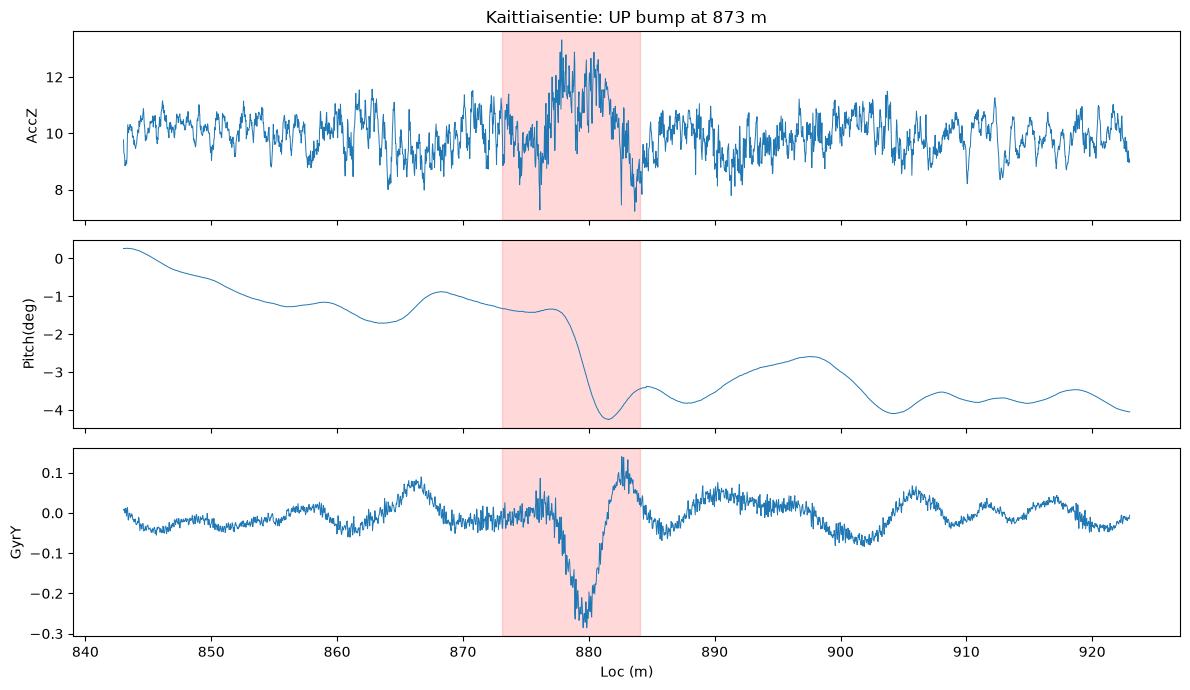

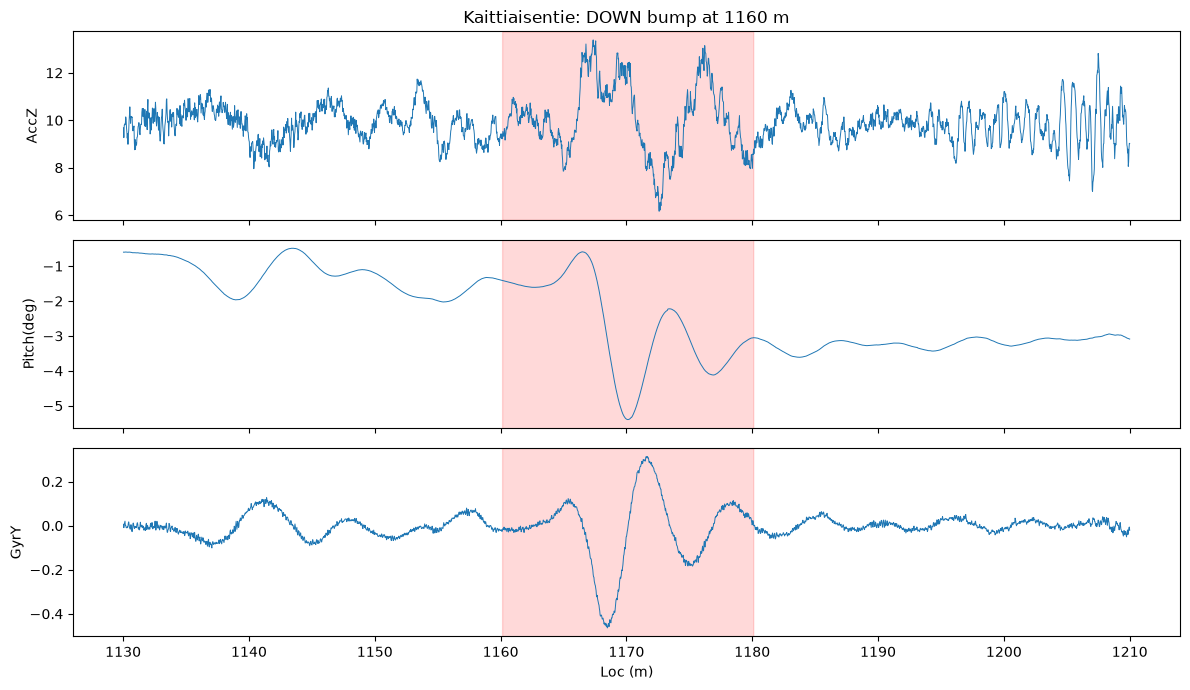

In [11]:
up_bump = 873      # start of a posneg = 1 bump
down_bump = 1160     # start of a posneg = 2 bump

plot_bump(k, up_bump, f"Kaittiaisentie: UP bump at {up_bump} m").savefig("figures/up_bump.png", dpi=150)
plot_bump(k, down_bump, f"Kaittiaisentie: DOWN bump at {down_bump} m").savefig("figures/down_bump.png", dpi=150)
plt.show()

* Not much clear difference visible therefore let's try other approach

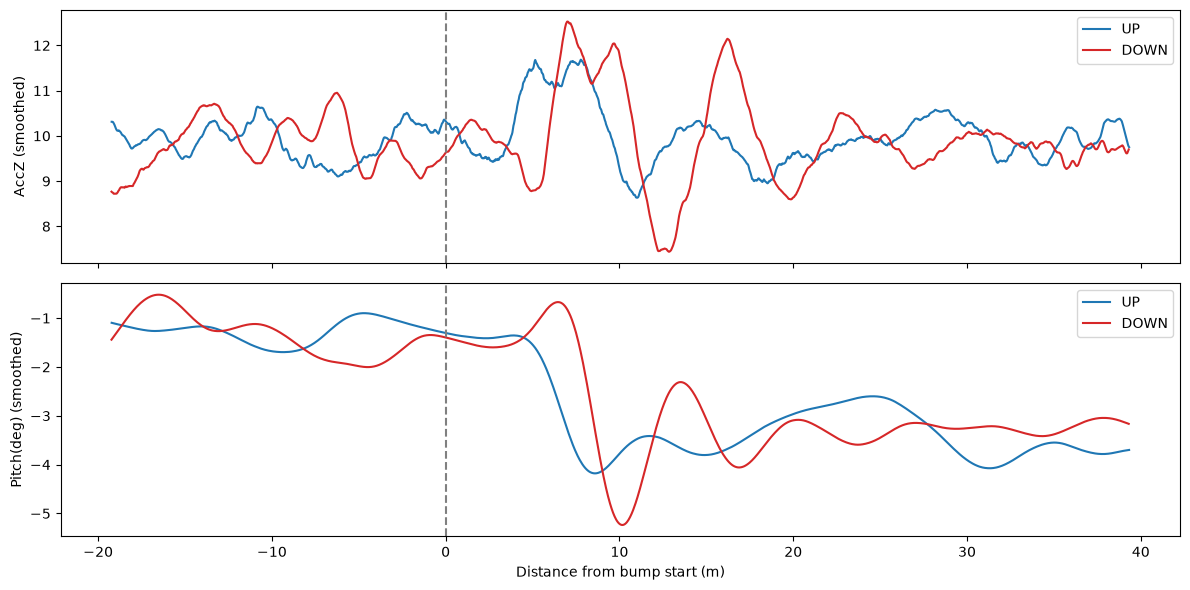

In [15]:
# Compare the two bumps in a single plot, with smoothing to reduce noise
def smoothed(df, start, col, window=50):
    part = df[df["Loc(m)"].between(start - 20, start + 40)]
    x = part["Loc(m)"] - start                            # 0 = where the bump starts
    y = part[col].rolling(window, center=True).mean()     # average over 50 neighbouring rows
    return x, y

fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
for ax, col in zip(axes, ["AccZ", "Pitch(deg)"]):
    for start, label, color in [(up_bump, "UP", "tab:blue"), (down_bump, "DOWN", "tab:red")]:
        x, y = smoothed(k, start, col)
        ax.plot(x, y, label=label, color=color)
    ax.axvline(0, color="grey", linestyle="--")
    ax.set_ylabel(col + " (smoothed)")
    ax.legend()
axes[-1].set_xlabel("Distance from bump start (m)")
plt.tight_layout()
plt.savefig("figures/up_vs_down_smoothed.png", dpi=150)
plt.show()

* after smoothing, the up and down bump differ in AccZ (the direction of the first swing and the amount of bouncing), consistent with physics. But this is one example of each, so it’s a hint, not proof.

#### Section 3: the same bump at three speeds

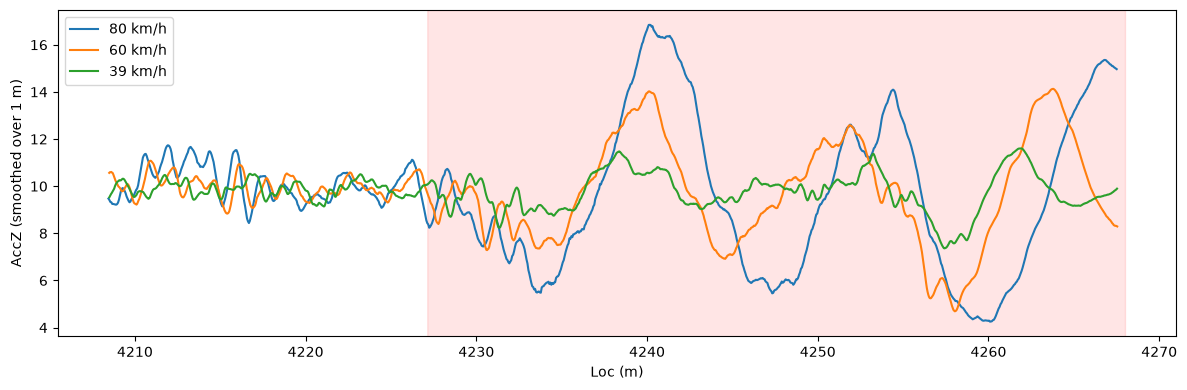

In [16]:
iisi = {name: d for name, d in data.items() if name.startswith("Iisingintie")}

center = 4228     # same bump in all three drives
fig, ax = plt.subplots(figsize=(12, 4))

for name, d in iisi.items():
    part = d[d["Loc(m)"].between(center - 20, center + 40)]
    rows_per_meter = 400 / part["Speed (m/s)"].mean()        # rows that cover 1 m of road
    window = int(rows_per_meter)                             # smooth over 1 m
    ax.plot(part["Loc(m)"], part["AccZ"].rolling(window, center=True).mean(),
            label=f"{d['Speed_kmh'].median():.0f} km/h")

ax.fill_between(part["Loc(m)"], 0, 1, where=part["muu"] == 1,
                transform=ax.get_xaxis_transform(), color="red", alpha=0.1)
ax.set_xlabel("Loc (m)")
ax.set_ylabel("AccZ (smoothed over 1 m)")
ax.legend()
plt.tight_layout()
plt.savefig("figures/same_bump_three_speeds.png", dpi=150)
plt.show()

In [ ]:
# how does the variation change with speed?
for name, d in iisi.items():
    near = d[d["Loc(m)"].between(center - 40, center + 60)]
    inside = near.loc[near["muu"] == 1, "AccZ"].std()
    outside = near.loc[near["muu"] == 0, "AccZ"].std()
    print(f"{d['Speed_kmh'].median():.0f} km/h | variation inside bump: {inside:.2f} | "
          f"outside: {outside:.2f} | ratio: {inside / outside:.1f}x")

80 km/h | variation inside bump: 3.09 | outside: 1.34 | ratio: 2.3x
60 km/h | variation inside bump: 2.01 | outside: 1.21 | ratio: 1.7x
39 km/h | variation inside bump: 0.94 | outside: 0.93 | ratio: 1.0x


* The ratio is not stable. Inside the bump, the variation more than triples from 39 to 80 km/h. Outside, on normal gravel, it grows only little. 

#### Why this happens?

* A frost heave is a long, smooth hump. At low speed the car rolls over it gently, so the vertical acceleration stays small. At higher speed, the same hump lifts the car in a shorter time, so the acceleration grows quickly, roughly with the square of speed: twice the speed gives about four times the acceleration from the bump. Gravel noise grows much less. So at 80 km/h the bump stands out clearly, and at 40 km/h it disappears into the noise.

* Therfore we need a sensor that doesn’t depend so much on speed

In [ ]:
# how does the variation change with speed?
rows = []
for name, d in iisi.items():
    near = d[d["Loc(m)"].between(center - 40, center + 60)]
    speed = round(d["Speed_kmh"].median())
    for col in ["AccZ", "Pitch(deg)", "GyrY"]:
        inside = near.loc[near["muu"] == 1, col].std()
        outside = near.loc[near["muu"] == 0, col].std()
        rows.append({"sensor": col, "speed": speed, "ratio": round(inside / outside, 1)})

print(pd.DataFrame(rows).pivot(index="sensor", columns="speed", values="ratio"))

speed        39   60   80
sensor                   
AccZ        1.0  1.7  2.3
GyrY        3.3  4.4  5.5
Pitch(deg)  2.6  2.8  3.4


* Rotation-based signals (Pitch, GyrY) show bumps much more clearly than vertical acceleration (AccZ), especially at low speed. Features should be built mainly from these.

In [20]:
# how many bumps of each size?
fh = stretches[stretches["muu"] == 1].copy()
fh["road"] = fh["file"].str.split("_").str[0]

real_bumps = fh.drop_duplicates(subset=["road", "start"])   # same road + same start = same bump

print("Real frost-heave bumps:", len(real_bumps))
print()
print(pd.crosstab(real_bumps["posneg"], real_bumps["vaikeus"], margins=True))

Real frost-heave bumps: 19

vaikeus  1  2  3  5  All
posneg                  
1        3  1  5  6   15
2        2  0  1  1    4
All      5  1  6  7   19


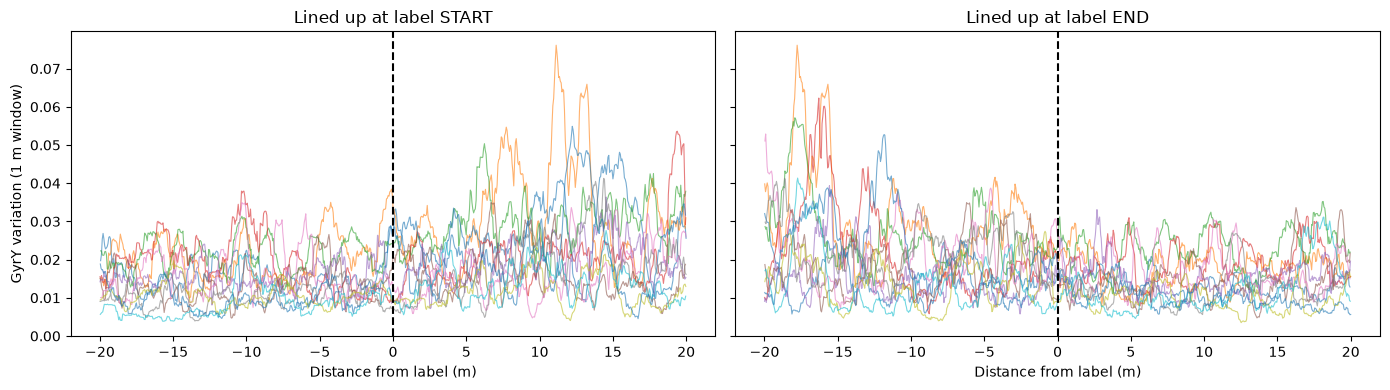

In [21]:
# do the labels line up with the signal?
d = data["Iisingintie_Acc1_m800_RDMC_2026-05-06_123750"]
window = int(400 / d["Speed (m/s)"].mean())                   # rows in 1 m of road
d = d.assign(gyr_var=d["GyrY"].rolling(window, center=True).std())

b = stretches[stretches["file"].str.contains("m800") & (stretches["muu"] == 1)]

fig, axes = plt.subplots(1, 2, figsize=(14, 4), sharey=True)
for _, r in b.iterrows():
    start, end = r["start"], r["start"] + r["length_m"]
    for ax, ref in zip(axes, [start, end]):
        part = d[d["Loc(m)"].between(ref - 20, ref + 20)]
        ax.plot(part["Loc(m)"] - ref, part["gyr_var"], linewidth=0.8, alpha=0.6)

for ax, title in zip(axes, ["Lined up at label START", "Lined up at label END"]):
    ax.axvline(0, color="black", linestyle="--")
    ax.set_title(title)
    ax.set_xlabel("Distance from label (m)")
axes[0].set_ylabel("GyrY variation (1 m window)")
plt.tight_layout()
plt.savefig("figures/label_alignment.png", dpi=150)
plt.show()

* The label starts before the shaking and ends after it. It’s not shifted in one direction. The labelled stretches are wider than the part the car actually feels, by a few meters at each end.

## Conclusions

**1. What a bump looks like**
- Inside labelled bumps the signal fluctuates more than on normal road, visible in AccZ, Pitch and GyrY.

**2. Up vs. down**
- After smoothing (moving average over ~1.4 m), the up and down bump differ in AccZ: the up bump first pushes the car upward, the down bump first lets it drop, which matches physics. Based on one example of each, so a hint, not proof.
- Only 4 of 19 real bumps are negative (`posneg = 2`), all on Kaittiaisentie. Up/down is treated as a secondary goal and is a limitation of the dataset.

**3. Effect of speed (bump at 4,228 m, Iisingintie, 3 drives)**
- The same bump gets much stronger with speed in AccZ (variation inside/outside: 1.0x at 39 km/h, 2.3x at 80 km/h). At low speed it is invisible in AccZ.
- Rotation signals are much better: GyrY 3.3x to 5.5x, Pitch 2.6x to 3.4x, clearly visible at every speed.
- Features should be built mainly from GyrY and Pitch, and speed must be an input to the model.

**4. Label alignment (11 bumps, 80 km/h drive)**
- The labelled stretches are wider than the part the car actually feels: shaking starts a few meters after the label start and ends several meters before the label end.
- When labelling windows: more than half labelled = bump, none = no bump, partial = left out.
- Some small bumps barely raise the signal, so they will be the hardest to detect.

**5. Bumps by type and size**
- 19 real frost-heave bumps (15 up, 4 down). Sizes 1, 2, 3 and 5 only.
- Size will be predicted in 3 groups: small (1–2): 6, medium (3): 6, large (5): 7.

**Other findings**
- AccZ is in m/s² (≈ 9.8 on calm road, gravity included).
- Sampling rate 400 Hz, so rows per meter depend on speed. Windows and smoothing must be defined in meters, not rows.

### Which columns are used for modelling

| Column | Use as model input? | Reason |
|---|---|---|
| AccX, AccY, AccZ |  Candidate | Vehicle motion. Tested on windows in 04 |
| GyrX, GyrY, GyrZ |  Candidate | Vehicle rotation. GyrY strongest in exploration |
| Roll(deg), Pitch(deg) |  Candidate | Vehicle angle. Pitch stable across speeds |
| Speed (m/s) |  Yes | Bump strength depends on speed |
| Speed_kmh |  No | Duplicate of Speed (m/s) |
| Loc(m) |  No (used for windowing) | Position along the road, not a property of the bump |
| Timer(ms) |  No | Time since start of recording |
| East(m), North(m) |  No (dashboard map only) | The model would memorise *where* bumps are instead of *what* they look like |
| CElev(m) |  No | Shows hills, not bumps |
| Yaw(deg) |  No | Driving direction |
| RBCSV_80(cf), RBCSV_60(cf) |  Ask supervisor | Unknown meaning |
| muu, posneg, vaikeus |  Targets | What we predict |